In [3]:
#Lab 4.4 —  Attention Mechanism (Intro)
#1. Toy Dataset
import torch
import torch.nn as nn
import torch.nn.functional as F

seqs = torch.randint(0, 10, (100, 6))
labels = (seqs.sum(1) % 2).long()

print("Sequences shape:", seqs.shape)
print("Labels shape:", labels.shape)

print("\nFirst 5 sequences:")
print(seqs[:5])

print("\nFirst 5 labels:")
print(labels[:5])


Sequences shape: torch.Size([100, 6])
Labels shape: torch.Size([100])

First 5 sequences:
tensor([[4, 4, 5, 2, 8, 0],
        [7, 4, 5, 1, 6, 5],
        [1, 8, 6, 6, 3, 9],
        [2, 9, 6, 3, 5, 5],
        [6, 2, 8, 4, 0, 0]])

First 5 labels:
tensor([1, 0, 1, 0, 0])


In [8]:
# 2. Attention Model

import torch
import torch.nn as nn
import torch.nn.functional as F

class AttentionClassifier(nn.Module):
    def __init__(self, vocab=10, emb=16, hidden=32):
        super().__init__()

        # Convert integers into embedding vectors
        self.emb = nn.Embedding(vocab, emb)

        # Process the sequence using GRU
        self.rnn = nn.GRU(emb, hidden, batch_first=True)

        # Calculate attention scores
        self.attn = nn.Linear(hidden, 1)

        # Classify into two classes: 0 or 1
        self.fc = nn.Linear(hidden, 2)

    def forward(self, x):
        h, _ = self.rnn(self.emb(x))

        # Calculate attention weights
        attn_w = torch.softmax(
            self.attn(h).squeeze(-1), dim=1
        )

        # Calculate context vector
        ctx = (h * attn_w.unsqueeze(-1)).sum(1)

        # Return class scores and attention weights
        return self.fc(ctx), attn_w


# Create model and optimizer
model = AttentionClassifier()
opt = torch.optim.Adam(model.parameters(), lr=0.01)

print(model)
print("Attention model created successfully!")


AttentionClassifier(
  (emb): Embedding(10, 16)
  (rnn): GRU(16, 32, batch_first=True)
  (attn): Linear(in_features=32, out_features=1, bias=True)
  (fc): Linear(in_features=32, out_features=2, bias=True)
)
Attention model created successfully!


In [5]:
#3. Train
for ep in range(5):
    out,attn = model(seqs)
    loss = F.cross_entropy(out, labels)
    opt.zero_grad(); loss.backward(); opt.step()
    print("epoch", ep, "loss", loss.item())

epoch 0 loss 0.6876531839370728
epoch 1 loss 0.6766659021377563
epoch 2 loss 0.6667109727859497
epoch 3 loss 0.6571184396743774
epoch 4 loss 0.6478865146636963


Text(0.5, 1.0, 'Attention weights (10 samp)')

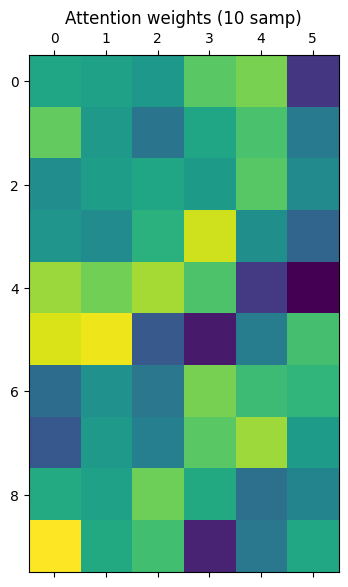

In [7]:
#4. Visualize attention weights
import matplotlib.pyplot as plt
plt.matshow(attn.detach().numpy()[:10]); plt.title("Attention weights (10 samp)")